# Smart Agriculture - Plant Disease Detection Using Leaf Image Processing

## Part 1: Environment Setup

### Check GPU:



In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Install required libraries

In [ ]:
!pip install -q opencv-python-headless scikit-image scikit-learn seaborn

### Import Libraries

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("Libraries imported successfully!")

Libraries imported successfully!


## Part 2: Dataset Collection

### Upload Kaggle API Key

In [5]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


### Configure Kaggle

In [6]:
!mkdir -p ~/.kaggle

!cp kaggle.json ~/.kaggle/

!chmod 600 ~/.kaggle/kaggle.json

!pip install -q kaggle

print("Kaggle configured successfully!")

Kaggle configured successfully!


### Download Dataset

In [7]:
!mkdir -p /content/plant_dataset

!kaggle datasets download \
    -d arjuntejaswi/plant-village \
    -p /content/plant_dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/arjuntejaswi/plant-village
License(s): unknown
100% 329M/329M [00:09<00:00, 37.7MB/s]



## Part 3: Dataset Exploration

### Check Dataset Folders

In [8]:
import os

DATASET_PATH = "/content/plant_dataset"

print("Dataset downloaded successfully!")
print("\nAvailable folders:\n")

for root, dirs, files_list in os.walk(DATASET_PATH):
    image_count = sum(
        f.lower().endswith(('.jpg', '.jpeg', '.png'))
        for f in files_list
    )

    if image_count > 0:
        print(os.path.basename(root), ":", image_count, "images")

Dataset downloaded successfully!

Available folders:

Tomato__Tomato_mosaic_virus : 373 images
Tomato_Leaf_Mold : 952 images
Tomato_Spider_mites_Two_spotted_spider_mite : 1676 images
Tomato_Bacterial_spot : 2127 images
Pepper__bell___Bacterial_spot : 997 images
Tomato__Tomato_YellowLeaf__Curl_Virus : 3208 images
Tomato_Early_blight : 1000 images
Potato___healthy : 152 images
Pepper__bell___healthy : 1478 images
Tomato__Target_Spot : 1404 images
Tomato_healthy : 1591 images
Potato___Early_blight : 1000 images
Tomato_Septoria_leaf_spot : 1771 images
Tomato_Late_blight : 1909 images
Potato___Late_blight : 1000 images


### Load Dataset and Assign Labels

In [9]:
import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

All libraries imported successfully!
TensorFlow Version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Visualize Class Distribution

In [10]:
DATASET_PATH = "/content/plant_dataset"

image_extensions = ('.jpg', '.jpeg', '.png')

class_dirs = []

for root, dirs, files_list in os.walk(DATASET_PATH):

    image_files = [
        f for f in files_list
        if f.lower().endswith(image_extensions)
    ]

    if image_files:
        class_dirs.append(root)

class_dirs = sorted(class_dirs)

class_names = [
    os.path.basename(folder)
    for folder in class_dirs
]

image_paths = []
labels = []

for label, folder in enumerate(class_dirs):

    for filename in os.listdir(folder):

        if filename.lower().endswith(image_extensions):

            image_paths.append(
                os.path.join(folder, filename)
            )

            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

NUM_CLASSES = len(class_names)

print("Total Images:", len(df))
print("Total Classes:", NUM_CLASSES)

print("\nClass Names:")

for i, name in enumerate(class_names):
    print(i, name)

print("\nDataset Preview:")
display(df.head())

Total Images: 20638
Total Classes: 15

Class Names:
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy

Dataset Preview:


,image_path,label
0,/content/plant_dataset/PlantVillage/Pepper__be...,0
1,/content/plant_dataset/PlantVillage/Pepper__be...,0
2,/content/plant_dataset/PlantVillage/Pepper__be...,0
3,/content/plant_dataset/PlantVillage/Pepper__be...,0
4,/content/plant_dataset/PlantVillage/Pepper__be...,0


### Visualize Class Distribution

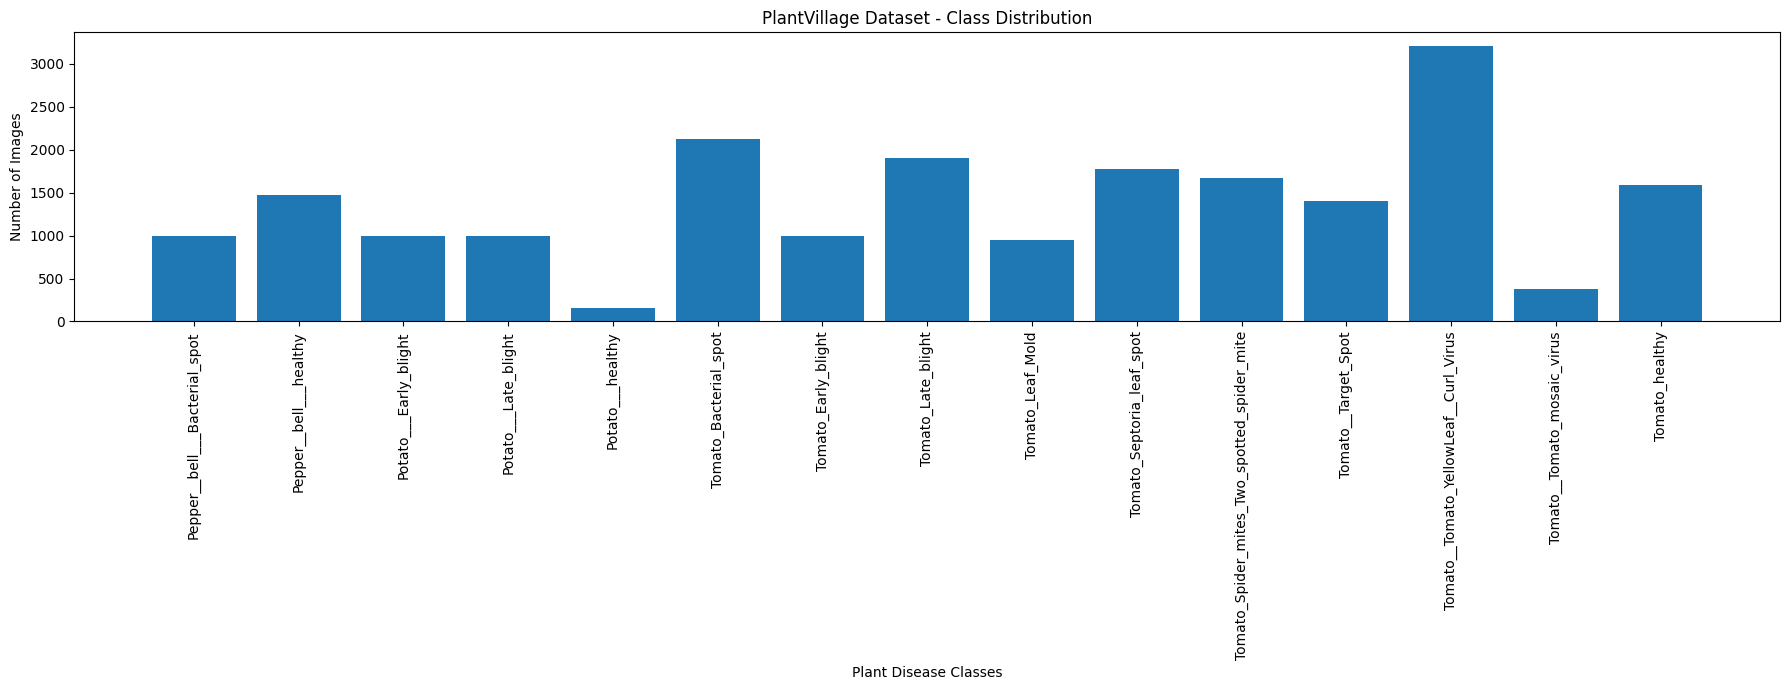

In [11]:
class_counts = df['label'].value_counts().sort_index()

plt.figure(figsize=(18, 7))

plt.bar(
    [class_names[i] for i in class_counts.index],
    class_counts.values
)

plt.title("PlantVillage Dataset - Class Distribution")
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Display Sample Leaf Images

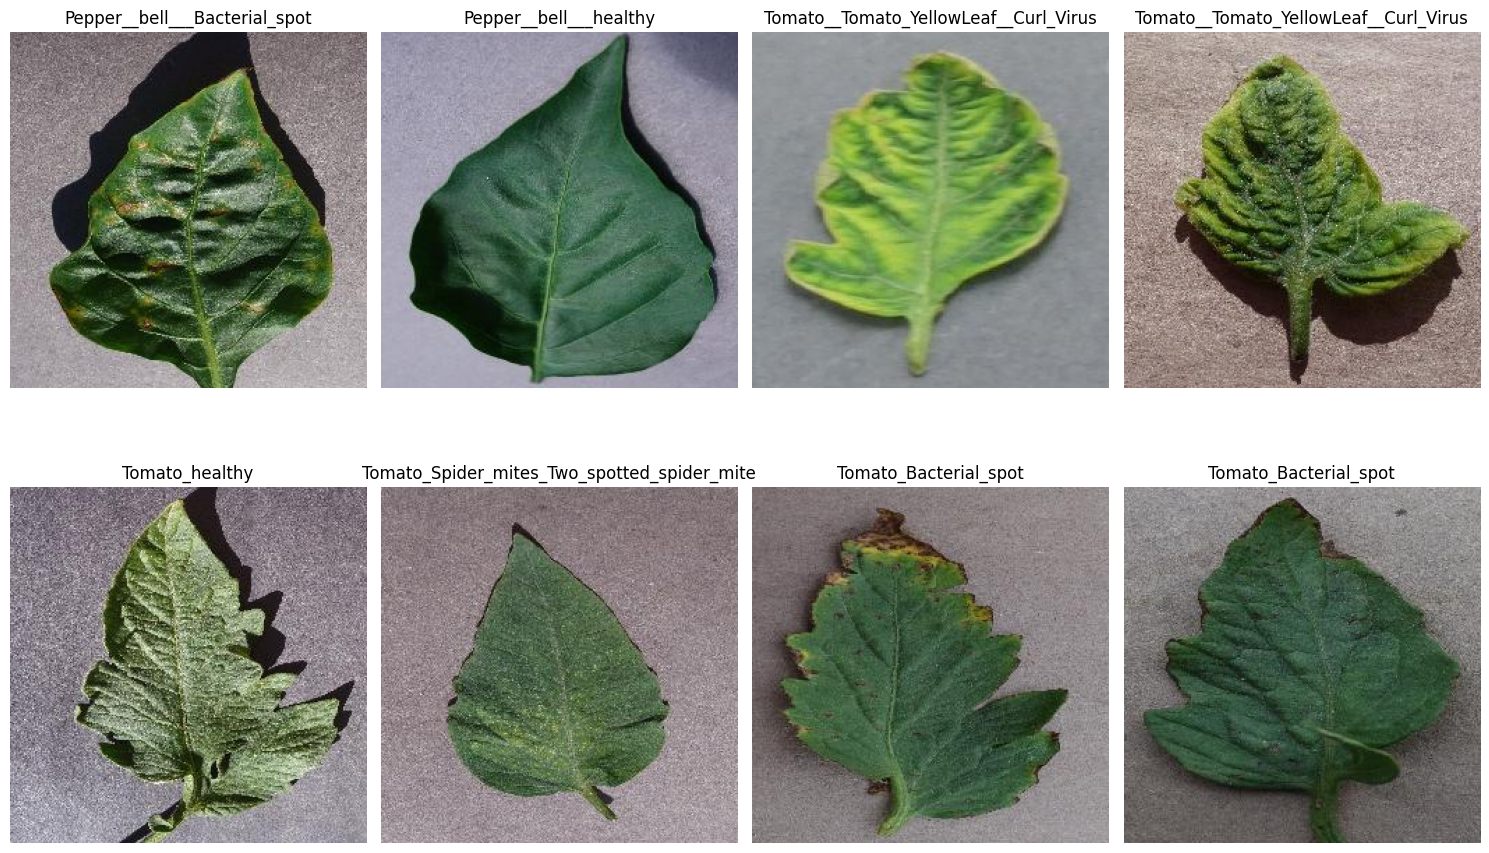

In [12]:
plt.figure(figsize=(15, 10))

for i in range(8):

    index = np.random.randint(0, len(df))

    image_path = df.iloc[index]['image_path']

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    label = df.iloc[index]['label']

    plt.subplot(2, 4, i + 1)

    plt.imshow(image)

    plt.title(class_names[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

## Part 4: Train, Validation and Test Split

### Split Dataset

In [13]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training Images: 14446
Validation Images: 3096
Testing Images: 3096

Total: 20638


In [14]:
IMG_SIZE = 224
BATCH_SIZE = 32

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(dataframe, training=False):

    paths = dataframe['image_path'].values

    labels_array = dataframe['label'].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels_array)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:

        dataset = dataset.shuffle(
            2000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)

val_ds = create_dataset(val_df)

test_ds = create_dataset(test_df)

print("Training, validation and testing datasets created!")

Training, validation and testing datasets created!


In [16]:
def segment_leaf(image_path):

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    hsv = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2HSV
    )

    lower_green = np.array([25, 20, 20])

    upper_green = np.array([100, 255, 255])

    mask = cv2.inRange(
        hsv,
        lower_green,
        upper_green
    )

    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    segmented = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    return image, mask, segmented

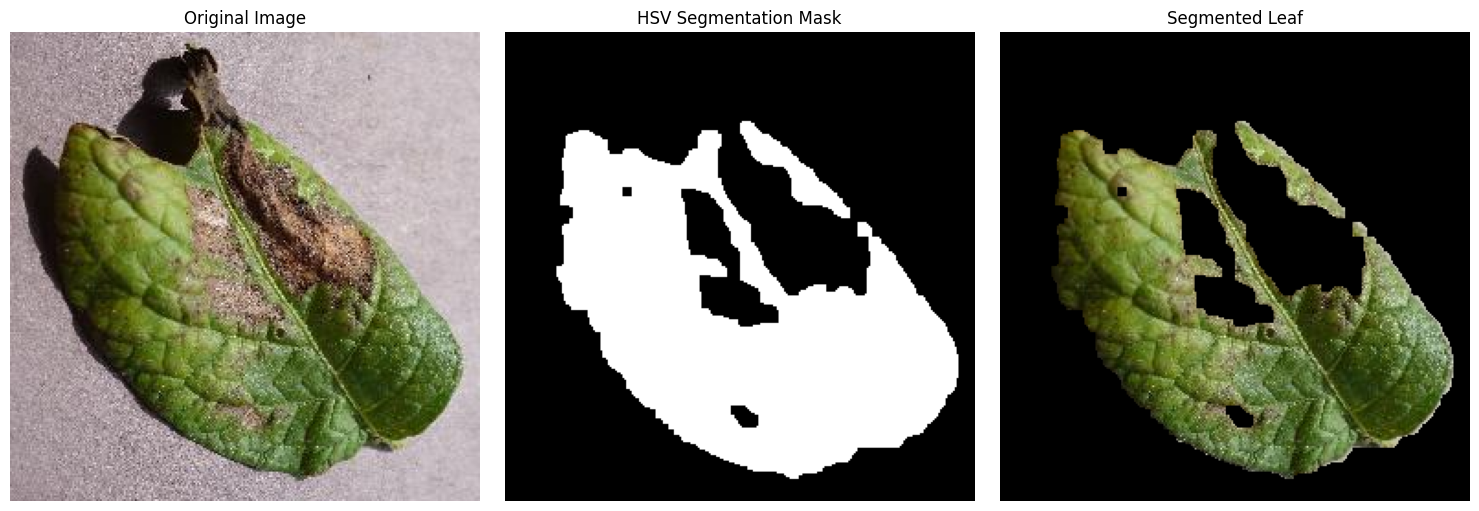

In [17]:
sample_path = train_df.iloc[0]['image_path']

original, mask, segmented = segment_leaf(sample_path)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title("HSV Segmentation Mask")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(segmented)
plt.title("Segmented Leaf")
plt.axis('off')

plt.tight_layout()
plt.show()

In [18]:
!pip install -q scikit-image

from skimage.feature import graycomatrix, graycoprops

In [19]:
def extract_features(image_path):

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    image = cv2.resize(
        image,
        (128, 128)
    )

    # Color feature extraction

    hsv = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2HSV
    )

    hist = cv2.calcHist(
        [hsv],
        [0, 1, 2],
        None,
        [8, 8, 8],
        [0, 180, 0, 256, 0, 256]
    )

    hist = cv2.normalize(
        hist,
        hist
    ).flatten()

    # Texture feature extraction

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    gray = (gray // 16).astype(np.uint8)

    glcm = graycomatrix(
        gray,
        distances=[1],
        angles=[0],
        levels=16,
        symmetric=True,
        normed=True
    )

    texture_features = []

    properties = [
        'contrast',
        'homogeneity',
        'energy',
        'correlation'
    ]

    for prop in properties:

        value = graycoprops(
            glcm,
            prop
        )[0, 0]

        texture_features.append(value)

    return np.concatenate([
        hist,
        np.array(texture_features)
    ])

In [20]:
features = extract_features(sample_path)

print("Extracted Features:", features)

print("\nFeature Vector Shape:", features.shape)

print("Feature extraction completed!")

Extracted Features: [2.00859227e-04 8.03436909e-04 8.03436909e-04 1.60687382e-03
 5.82491746e-03 2.18936559e-02 4.29838747e-02 2.00859227e-04
 3.21374764e-03 6.02577673e-03 3.41460691e-03 6.02577673e-03
 1.38592869e-02 2.22953744e-02 8.83780606e-03 6.02577697e-04
 1.12481164e-02 1.06455395e-02 7.43179163e-03 3.15348990e-02
 4.17787209e-02 3.55520844e-02 4.82062157e-03 0.00000000e+00
 2.37013884e-02 6.82921382e-03 2.24962328e-02 2.83211507e-02
 1.86799075e-02 6.42749527e-03 1.00429612e-03 0.00000000e+00
 2.30988115e-02 1.50644416e-02 1.76756121e-02 5.22234011e-03
 6.02577697e-04 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.60687380e-02 1.58678796e-02 5.62405819e-03 1.40601455e-03
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.18506942e-02 8.43608752e-03 6.02577697e-04 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 6.02577673e-03 1.80773309e-03 2.00859227e-04 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.0

In [21]:
IMG_SIZE = 224

NUM_CLASSES = len(class_names)

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.15),

    layers.RandomContrast(0.1)

])

base_model = EfficientNetB0(

    include_top=False,

    weights='imagenet',

    input_shape=(IMG_SIZE, IMG_SIZE, 3)

)

base_model.trainable = False

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

model = models.Model(
    inputs,
    outputs
)

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,073,906 (15.54 MB)

 Trainable params: 21,775 (85.06 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [22]:
class_weights_array = compute_class_weight(

    class_weight='balanced',

    classes=np.unique(train_df['label']),

    y=train_df['label']

)

class_weights = dict(
    enumerate(class_weights_array)
)

print("Class Weights:")
print(class_weights)

Class Weights:
{0: np.float64(1.3797516714422158), 1: np.float64(0.9304991948470209), 2: np.float64(1.3758095238095238), 3: np.float64(1.3758095238095238), 4: np.float64(9.08553459119497), 5: np.float64(0.646787553167674), 6: np.float64(1.3758095238095238), 7: np.float64(0.7208582834331337), 8: np.float64(1.446046046046046), 9: np.float64(0.7766666666666666), 10: np.float64(0.8210287013356067), 11: np.float64(0.9797219396405561), 12: np.float64(0.4289829250185598), 13: np.float64(3.689910600255428), 14: np.float64(0.8645122681029324)}


In [23]:
callbacks = [

    EarlyStopping(

        monitor='val_loss',

        patience=5,

        restore_best_weights=True

    ),

    ReduceLROnPlateau(

        monitor='val_loss',

        factor=0.2,

        patience=3,

        min_lr=1e-7

    ),

    ModelCheckpoint(

        filepath='/content/best_plant_model.keras',

        monitor='val_loss',

        save_best_only=True

    )

]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [24]:
history1 = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20,

    class_weight=class_weights,

    callbacks=callbacks

)

Epoch 1/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 75s 117ms/step - accuracy: 0.7124 - loss: 0.9105 - val_accuracy: 0.8666 - val_loss: 0.4256 - learning_rate: 0.0010
Epoch 2/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - accuracy: 0.8468 - loss: 0.4674 - val_accuracy: 0.8973 - val_loss: 0.3266 - learning_rate: 0.0010
Epoch 3/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 49s 104ms/step - accuracy: 0.8692 - loss: 0.3765 - val_accuracy: 0.9112 - val_loss: 0.2747 - learning_rate: 0.0010
Epoch 4/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 81s 103ms/step - accuracy: 0.8798 - loss: 0.3459 - val_accuracy: 0.9044 - val_loss: 0.2853 - learning_rate: 0.0010
Epoch 5/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - accuracy: 0.8879 - loss: 0.3098 - val_accuracy: 0.9189 - val_loss: 0.2389 - learning_rate: 0.0010
Epoch 6/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - accuracy: 0.8944 - loss: 0.3035 - val_accuracy: 0.9125 - val_loss: 0.2619 - learning_rate: 0.0010
Epoch 7/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 50s 105ms/step - accuracy: 0.8

In [25]:
base_model.trainable = True

# Unfreeze only the last 30 layers

for layer in base_model.layers[:-30]:

    layer.trainable = False

# Keep Batch Normalization layers frozen

for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):

        layer.trainable = False

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

history2 = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    class_weight=class_weights,

    callbacks=callbacks

)

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 77s 131ms/step - accuracy: 0.9217 - loss: 0.2229 - val_accuracy: 0.9467 - val_loss: 0.1586 - learning_rate: 1.0000e-05
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 54s 115ms/step - accuracy: 0.9241 - loss: 0.2099 - val_accuracy: 0.9512 - val_loss: 0.1500 - learning_rate: 1.0000e-05
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 53s 114ms/step - accuracy: 0.9287 - loss: 0.1992 - val_accuracy: 0.9541 - val_loss: 0.1437 - learning_rate: 1.0000e-05
Epoch 4/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - accuracy: 0.9338 - loss: 0.1848 - val_accuracy: 0.9551 - val_loss: 0.1439 - learning_rate: 1.0000e-05
Epoch 5/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 53s 114ms/step - accuracy: 0.9383 - loss: 0.1735 - val_accuracy: 0.9570 - val_loss: 0.1404 - learning_rate: 1.0000e-05
Epoch 6/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 53s 114ms/step - accuracy: 0.9404 - loss: 0.1690 - val_accuracy: 0.9583 - val_loss: 0.1301 - learning_rate: 1.0000e-05
Epoch 7/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 54s 11

In [26]:
# Save the best Stage 1 model
model.save('/content/stage1_model.keras')

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

finetune_callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        '/content/stage2_model.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=finetune_callbacks
)

model.save('/content/stage2_final_model.keras')

print("Fine-tuning completed!")

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 69s 122ms/step - accuracy: 0.9551 - loss: 0.1270 - val_accuracy: 0.9671 - val_loss: 0.1080 - learning_rate: 1.0000e-05
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 56s 121ms/step - accuracy: 0.9548 - loss: 0.1220 - val_accuracy: 0.9667 - val_loss: 0.1017 - learning_rate: 1.0000e-05
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 55s 115ms/step - accuracy: 0.9563 - loss: 0.1195 - val_accuracy: 0.9687 - val_loss: 0.0997 - learning_rate: 1.0000e-05
Epoch 4/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - accuracy: 0.9574 - loss: 0.1133 - val_accuracy: 0.9683 - val_loss: 0.1008 - learning_rate: 1.0000e-05
Epoch 5/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 53s 113ms/step - accuracy: 0.9556 - loss: 0.1212 - val_accuracy: 0.9719 - val_loss: 0.0929 - learning_rate: 1.0000e-05
Epoch 6/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 53s 114ms/step - accuracy: 0.9571 - loss: 0.1122 - val_accuracy: 0.9722 - val_loss: 0.0913 - learning_rate: 1.0000e-05
Epoch 7/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 52s 11

In [27]:
stage1_model = tf.keras.models.load_model(
    '/content/stage1_model.keras'
)

stage2_model = tf.keras.models.load_model(
    '/content/stage2_model.keras'
)

stage1_loss = stage1_model.evaluate(
    val_ds, verbose=0
)[0]

stage2_loss = stage2_model.evaluate(
    val_ds, verbose=0
)[0]

print("Stage 1 Validation Loss:", stage1_loss)
print("Stage 2 Validation Loss:", stage2_loss)

if stage2_loss < stage1_loss:
    model = stage2_model
    print("Selected: Fine-tuned Model")
else:
    model = stage1_model
    print("Selected: Stage 1 Model")

model.save('/content/plant_disease_model.keras')

Stage 1 Validation Loss: 0.10401178896427155
Stage 2 Validation Loss: 0.08085383474826813
Selected: Fine-tuned Model


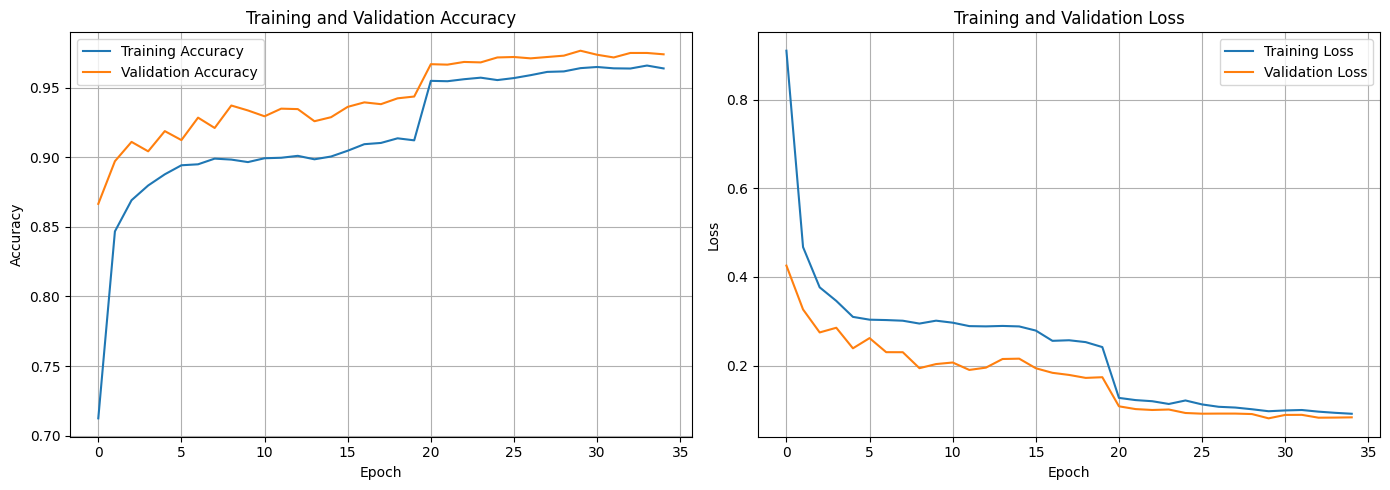

In [28]:
accuracy = (
    history1.history['accuracy']
    + history2.history['accuracy']
)

val_accuracy = (
    history1.history['val_accuracy']
    + history2.history['val_accuracy']
)

loss = (
    history1.history['loss']
    + history2.history['loss']
)

val_loss = (
    history1.history['val_loss']
    + history2.history['val_loss']
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(accuracy, label='Training Accuracy')
plt.plot(val_accuracy, label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [29]:
test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("\nFinal Model Evaluation")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

97/97 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9674 - loss: 0.0886

Final Model Evaluation
Test Loss: 0.08861736208200455
Test Accuracy: 96.7377245426178 %


In [30]:
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

y_prob = model.predict(test_ds)

y_pred = np.argmax(
    y_prob,
    axis=1
)

print("Predictions generated successfully!")

97/97 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step
Predictions generated successfully!


In [31]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )
)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.99      1.00      0.99       149
                     Pepper__bell___healthy       1.00      0.99      1.00       221
                      Potato___Early_blight       0.98      1.00      0.99       150
                       Potato___Late_blight       0.99      0.96      0.98       150
                           Potato___healthy       0.85      0.96      0.90        23
                      Tomato_Bacterial_spot       0.98      0.97      0.97       319
                        Tomato_Early_blight       0.95      0.87      0.91       150
                         Tomato_Late_blight       0.98      0.96      0.97       287
                           Tomato_Leaf_Mold       0.99      0.97      0.98       143
                  Tomato_Septoria_leaf_spot       0.97      0.95      0.96       266
Tomato_Spider_mites_Two_spotted_spider_mite       0.95      0.92

In [32]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average='macro',
    zero_division=0
)

print("MODEL PERFORMANCE")
print("-------------------------")

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

MODEL PERFORMANCE
-------------------------
Accuracy  : 96.74%
Precision : 95.94%
Recall    : 96.67%
F1 Score  : 96.23%


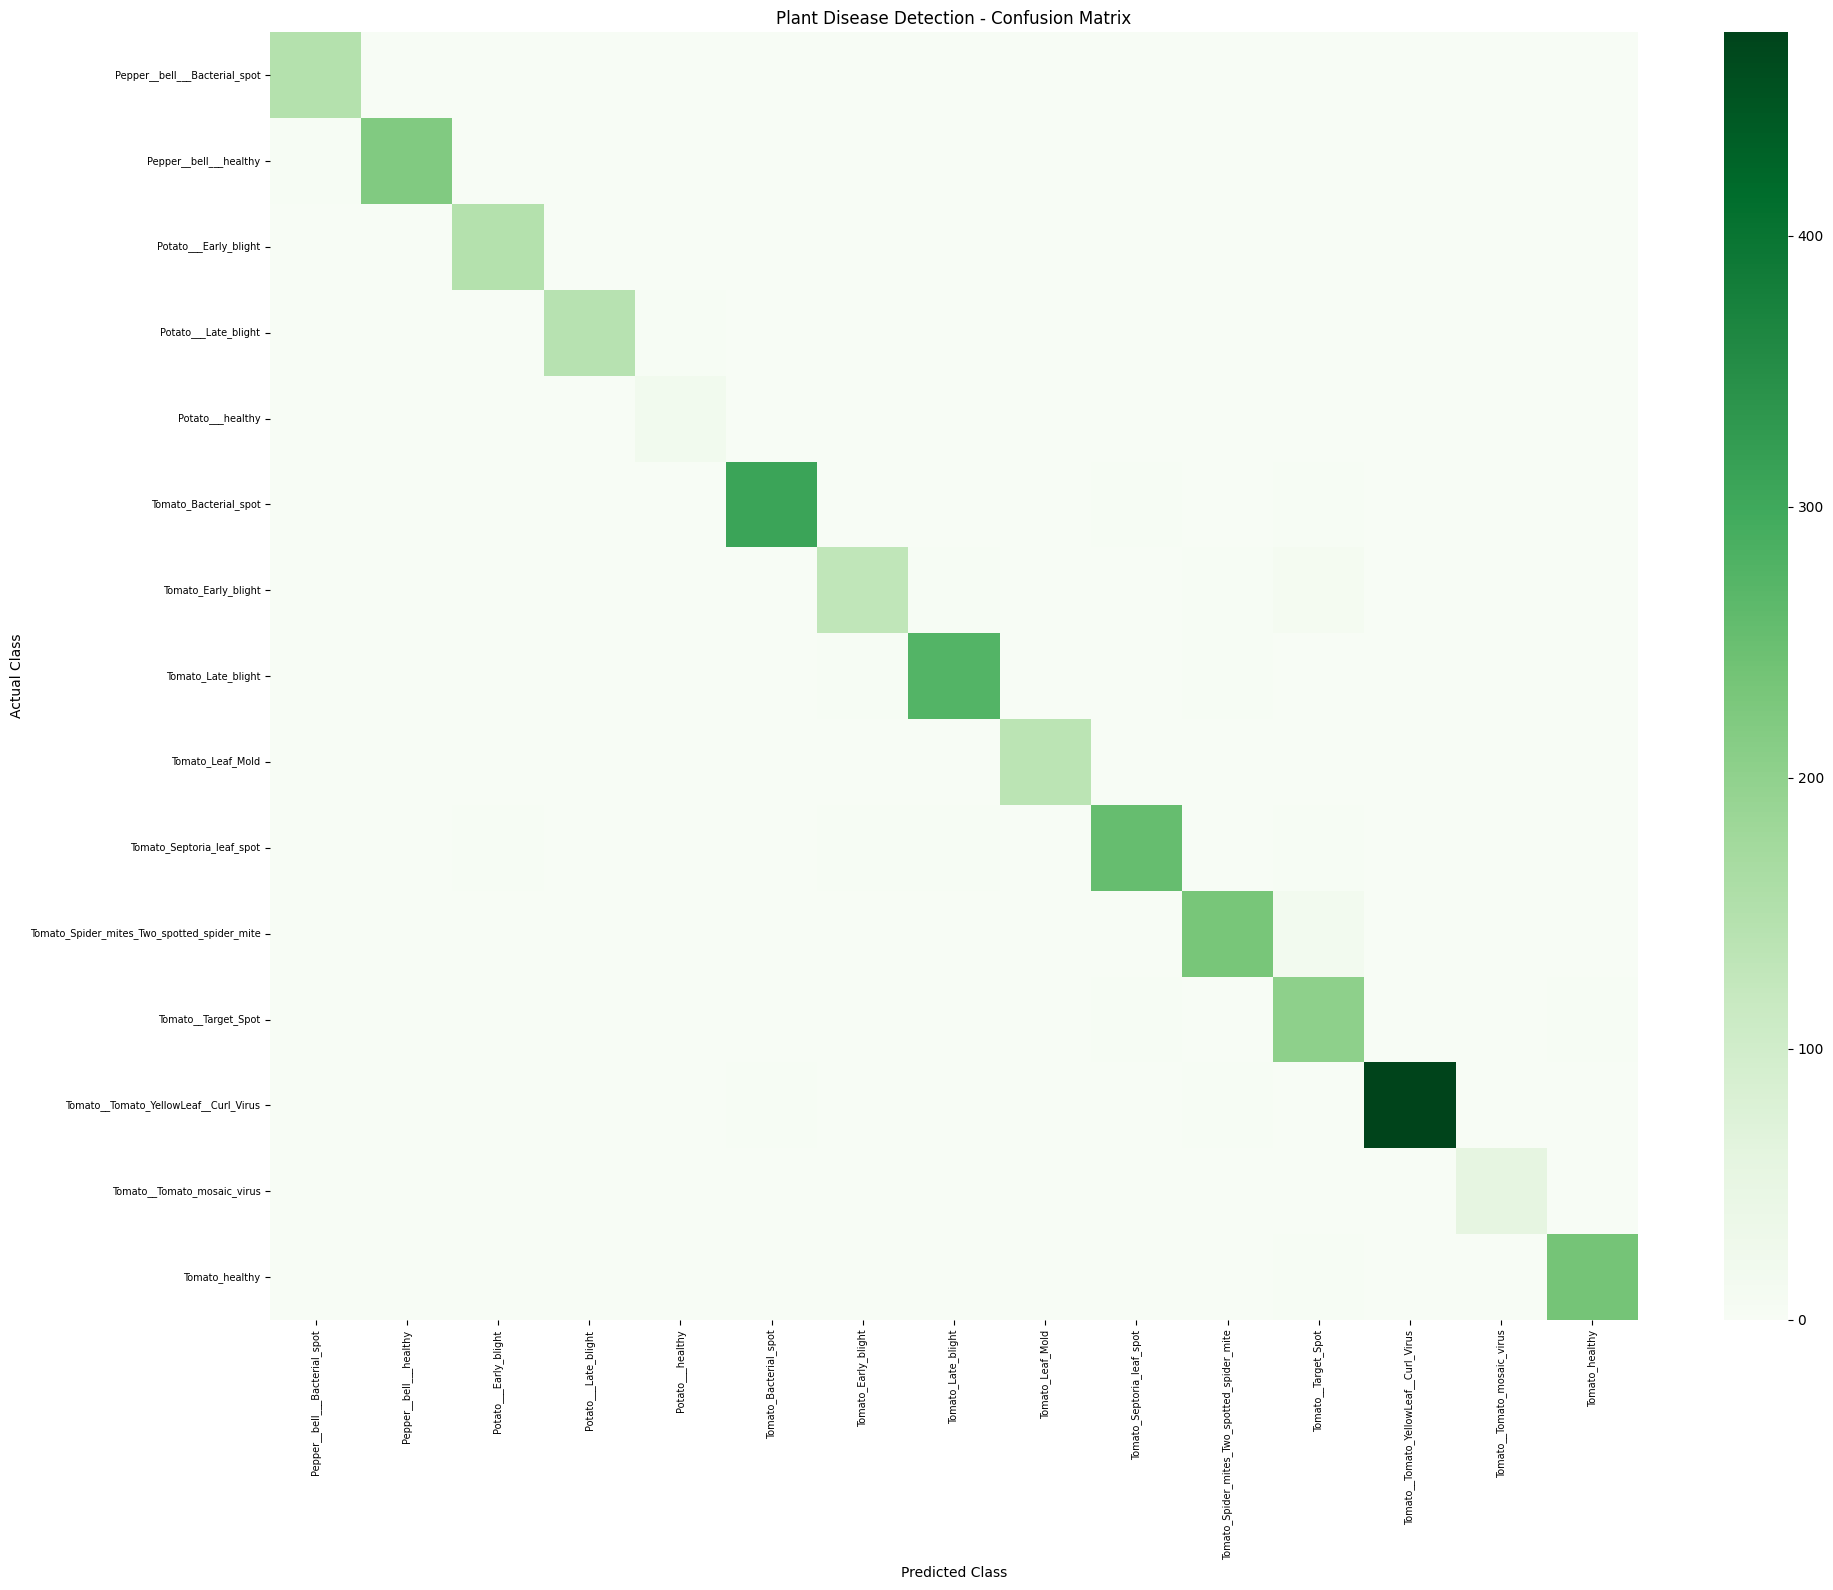

In [33]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Plant Disease Detection - Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(rotation=90, fontsize=7)

plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()

plt.show()

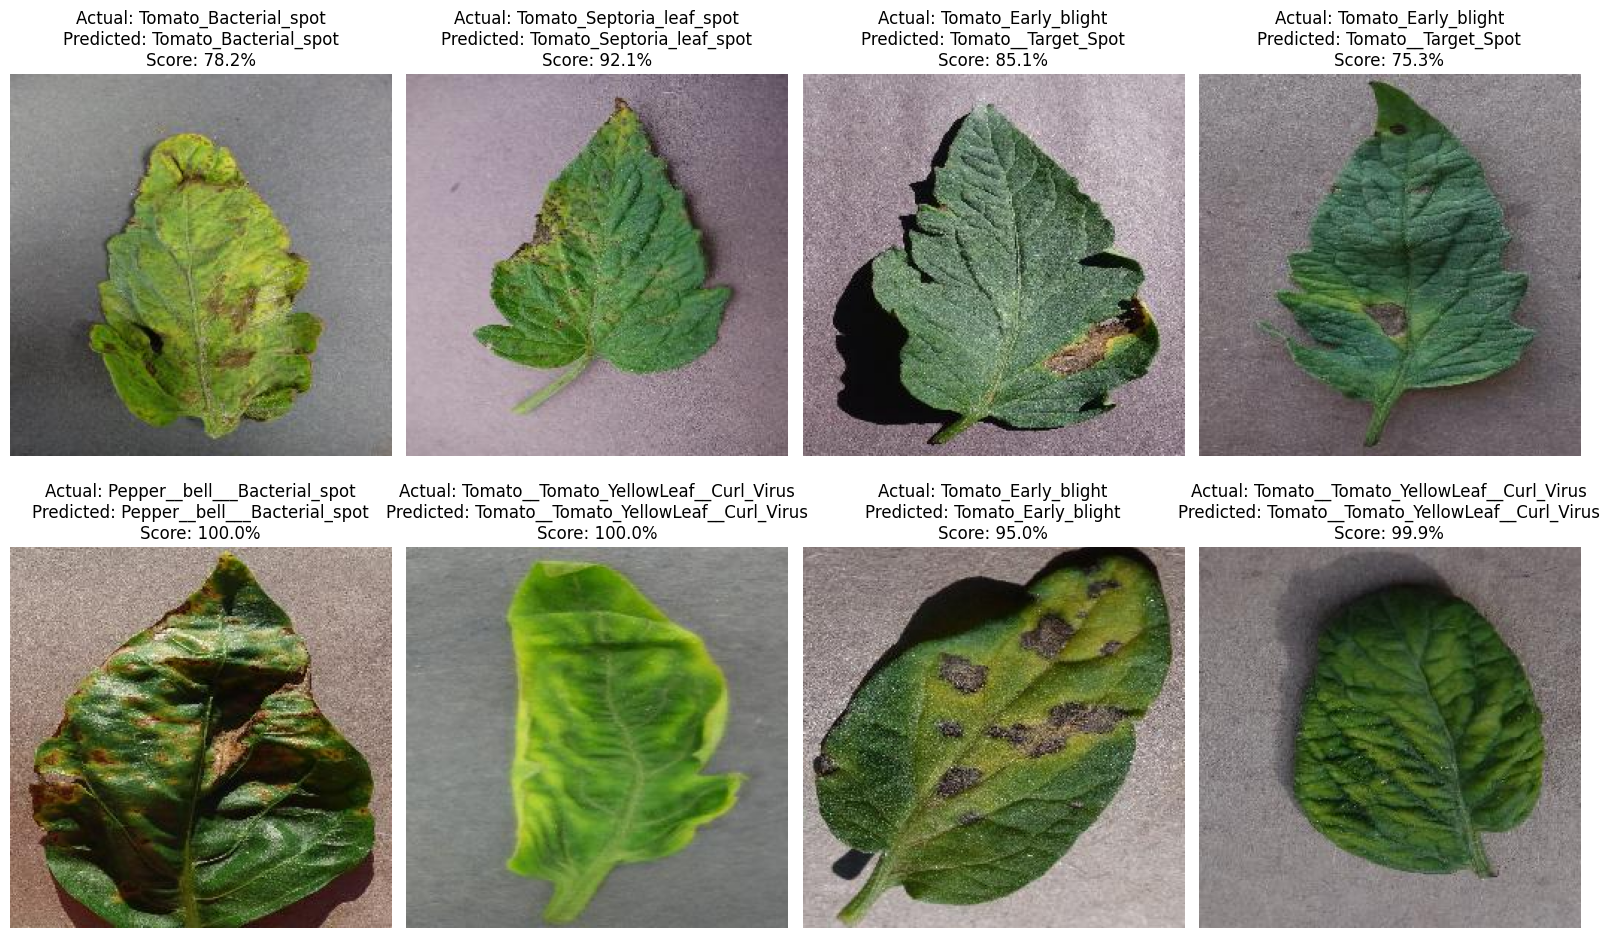

In [34]:
plt.figure(figsize=(16, 10))

for i in range(8):

    index = np.random.randint(0, len(y_true))

    image, _ = test_df.iloc[index][
        ['image_path', 'label']
    ]

    actual = y_true[index]

    predicted = y_pred[index]

    img = cv2.imread(image)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    confidence = y_prob[index][predicted] * 100

    plt.subplot(2, 4, i + 1)

    plt.imshow(img)

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"Score: {confidence:.1f}%"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

## Part 10: Test with a New Leaf Image

In [38]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded Image:", image_path)

Saving images (1).jpg to images (1).jpg
Uploaded Image: images (1).jpg


In [39]:
def predict_disease(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Invalid image file!")

    original = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    resized = cv2.resize(
        original,
        (IMG_SIZE, IMG_SIZE)
    )

    input_image = np.expand_dims(
        resized.astype(np.float32),
        axis=0
    )

    predictions = model.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    confidence = predictions[predicted_index] * 100

    predicted_class = class_names[predicted_index]

    print("\n===== PLANT DISEASE DETECTION =====")

    print("Predicted Class:", predicted_class)

    print(f"Model Confidence Score: {confidence:.2f}%")

    if confidence < 60:
        print("Warning: Low confidence. Manual inspection recommended.")

    plt.figure(figsize=(7, 7))

    plt.imshow(original)

    plt.title(
        f"{predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis('off')

    plt.show()

    return predicted_class, confidence


===== PLANT DISEASE DETECTION =====
Predicted Class: Pepper__bell___Bacterial_spot
Model Confidence Score: 100.00%


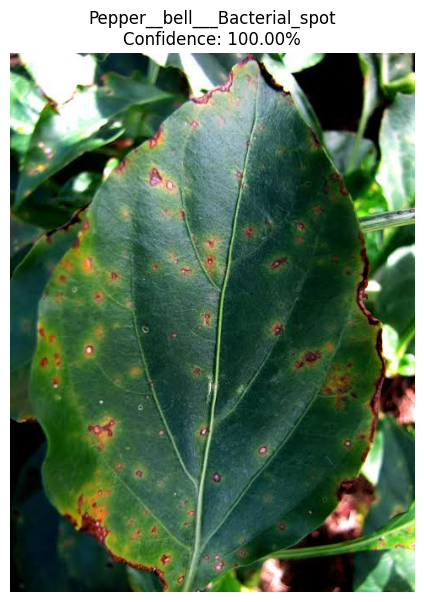

In [40]:
result = predict_disease(image_path)

## Save project

In [41]:
model.save(
    "/content/plant_disease_model.keras"
)

print("Model saved successfully!")

Model saved successfully!


In [42]:
with open(
    "/content/class_names.json",
    "w"
) as f:

    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


In [43]:
from google.colab import files

files.download(
    "/content/plant_disease_model.keras"
)

files.download(
    "/content/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>